# Project 19: Unsupervised Anomaly Detection with Deep Autoencoders

This project implements a bottleneck Autoencoder ($784 \to 64 \to 16 \to 64 \to 784$) for anomaly detection.
Trained solely on in-distribution digits, it detects out-of-distribution anomalous inputs via high reconstruction error.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from neurogebra.builders.model_builder import ModelBuilder
from neurogebra.datasets import Datasets

np.random.seed(42)
(X_mnist, y_mnist), _ = Datasets.load_mnist(flatten=True, verbose=False)
X_norm = X_mnist / 255.0

# In-distribution: digit 0 (1,000 samples)
X_normal = X_norm[y_mnist == 0][:1000]
# Anomalous distribution: digit 1 + random noisy images (200 samples)
X_anomaly = np.vstack([
    X_norm[y_mnist == 1][:100],
    np.random.uniform(0, 1, size=(100, 784)),
])
print(f'[INFO] Normal samples: {len(X_normal)}, Anomaly test samples: {len(X_anomaly)}')


[INFO] Normal samples: 1000, Anomaly test samples: 200


In [2]:
# Build Symmetric Bottleneck Autoencoder
builder = ModelBuilder()
autoencoder = builder.Sequential([
    builder.Dense(64, activation='relu'),
    builder.Dense(16, activation='relu'),  # Latent Bottleneck
    builder.Dense(64, activation='relu'),
    builder.Dense(784, activation='sigmoid'),
], name='AnomalyAutoencoder')

autoencoder.compile(loss='mse', optimizer='adam', learning_rate=0.003)
autoencoder.fit(X_normal[:800], X_normal[:800], epochs=7, batch_size=32, validation_split=0.15)
print('[SUCCESS] Autoencoder trained on normal distribution.')



Compiling model...
   Loss: mse
   Optimizer: adam (lr=0.003)
   Metrics: accuracy
   Model compiled successfully.


 Training AnomalyAutoencoder...

   Training samples: 800
   Epochs: 7
   Batch size: 32


Execution plan:

1.  The model will see 680 training examples
    It learns patterns by adjusting its weights

2.  This process repeats 7 times (epochs)
    Each time, the model gets better at predictions

3.  After each epoch, we test on 120 validation examples
    This tells us if the model is learning or just memorizing

Let's begin.


  Epoch   1/7 ████░░░░░░░░░░░░░░░░░░░░░░░░░░ loss: 0.1972 - acc: 0.0000 - val_loss: 0.0825 - val_acc: 0.0000 - 0.1s
  Epoch   2/7 ████████░░░░░░░░░░░░░░░░░░░░░░ loss: 0.0196 - acc: 0.0000 - val_loss: 0.0002 - val_acc: 0.0000 - 0.1s
  Epoch   3/7 ████████████░░░░░░░░░░░░░░░░░░ loss: 0.0000 - acc: 0.0000 - val_loss: 0.0000 - val_acc: 0.0000 - 0.1s
  Epoch   4/7 █████████████████░░░░░░░░░░░░░ loss: 0.0000 - acc: 0.0000 - val_loss: 0.0000 - val_acc: 

Anomaly Detection Threshold (95th percentile): 0.00000
Mean Reconstruction Error (Normal):            0.00000
Mean Reconstruction Error (Anomaly):           0.16647


<string>:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


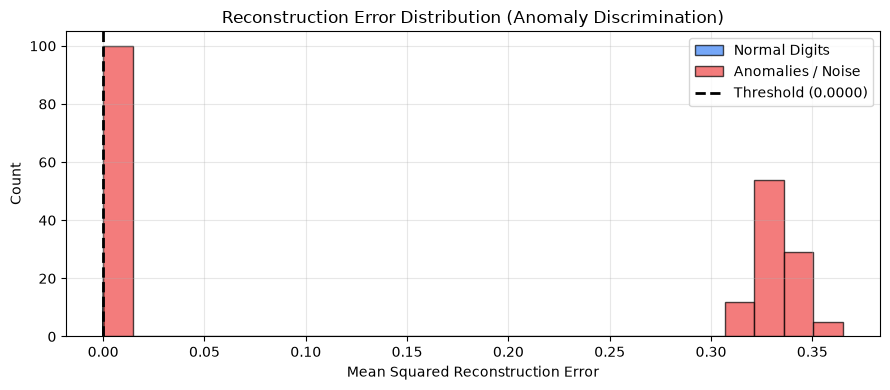

In [3]:
# Compute Reconstruction Errors
recon_normal = autoencoder.predict(X_normal[800:1000])
errors_normal = np.mean((X_normal[800:1000] - recon_normal)**2, axis=1)

recon_anomaly = autoencoder.predict(X_anomaly)
errors_anomaly = np.mean((X_anomaly - recon_anomaly)**2, axis=1)

threshold = float(np.percentile(errors_normal, 95))
print(f'Anomaly Detection Threshold (95th percentile): {threshold:.5f}')
print(f'Mean Reconstruction Error (Normal):            {np.mean(errors_normal):.5f}')
print(f'Mean Reconstruction Error (Anomaly):           {np.mean(errors_anomaly):.5f}')

plt.figure(figsize=(9, 4))
plt.hist(errors_normal, bins=25, alpha=0.7, label='Normal Digits', color='#3b82f6', edgecolor='black')
plt.hist(errors_anomaly, bins=25, alpha=0.7, label='Anomalies / Noise', color='#ef4444', edgecolor='black')
plt.axvline(threshold, color='black', linestyle='--', lw=2, label=f'Threshold ({threshold:.4f})')
plt.title('Reconstruction Error Distribution (Anomaly Discrimination)')
plt.xlabel('Mean Squared Reconstruction Error')
plt.ylabel('Count')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
